# 02. Modeling, threshold selection and model explanation

This notebook explains what `python -m churn.train` does and **why** it does it that way.
The code itself lives in `src/churn/`; the notebook only calls it and shows the results.
That way the code can be tested and reused by the API, while the notebook stays readable.

> Run `make train` first (≈30 seconds). It creates the model in `models/`
> and the plots in `reports/figures/`.

In [1]:
import json

import pandas as pd
from IPython.display import Image, display
from sklearn.model_selection import train_test_split

from churn import config
from churn.data import load_dataset
from churn.predict import ChurnModel

report = json.loads((config.REPORTS_DIR / "metrics.json").read_text())
model = ChurnModel.load()
X, y = load_dataset()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.RANDOM_STATE
)
print(f"Selected model: {report['selected_model']}, threshold: {report['threshold']:.2f}")

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Selected model: xgboost, threshold: 0.61


## 1. Validation scheme

```
7043 customers ──stratified split──► train 80% (5634)  ──► 5-fold CV: model comparison
                                   │                     └─► out-of-fold predictions: threshold choice
                                   └► test 20% (1409)    ──► one final evaluation
```

**Why:**
* **The test set is put aside immediately** and looked at once, at the very end. Choosing the model or the
  threshold on the test set would make the estimate optimistically biased (we would "fit" decisions to it).
* **Cross-validation on train** gives not a single number but a mean ± spread across 5 folds.
  That shows whether a difference between models is real or just noise.
* **All preprocessing lives inside the `Pipeline`.** The scaler and one-hot encoder are fitted only on the
  training folds, so there is no data leakage.

## 2. Comparing models

| Model | Why it is on the list |
|---|---|
| `baseline` | Always predicts the average rate. The floor: a model that does not beat it is useless. |
| `logreg` | Logistic regression. Simple, fast, interpretable. A strong baseline for tabular data. |
| `random_forest` | Bagged trees: robust to noise, captures non-linearities. |
| `xgboost`, `lightgbm` | Gradient boosting, the industry standard for tabular data. |

**Metrics:**
* **ROC-AUC**: the probability that a random churner gets a higher score than a random loyal customer.
  Independent of the threshold.
* **PR-AUC (average precision)**: the area under the precision-recall curve. More sensitive to quality on the
  rarer class, so we select the model by it. For a random model PR-AUC equals the churn rate (0.265).

In [2]:
cv = pd.DataFrame(report["cv"]).T
cv[["roc_auc_mean", "roc_auc_std", "pr_auc_mean", "pr_auc_std", "fit_seconds"]].round(4)

,roc_auc_mean,roc_auc_std,pr_auc_mean,pr_auc_std,fit_seconds
baseline,0.5000,0.0000,0.2654,0.0001,0.35
logreg,0.8473,0.0115,0.6596,0.0160,0.51
random_forest,0.8484,0.0098,0.6622,0.0237,6.78
xgboost,0.8473,0.0104,0.6635,0.0224,1.48
lightgbm,0.8422,0.0093,0.6540,0.0218,2.24


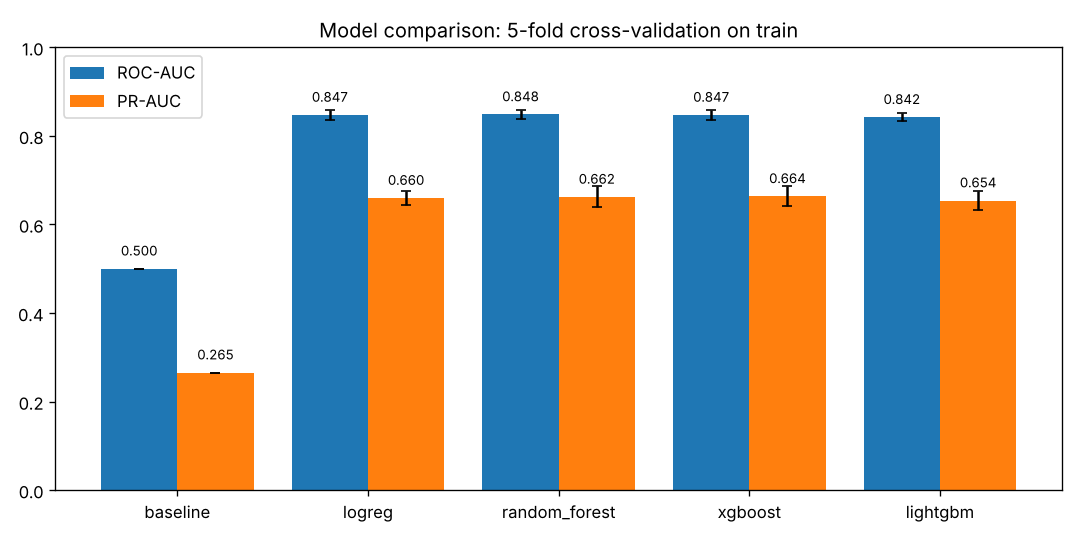

In [3]:
display(Image(config.FIGURES_DIR / "model_comparison.png"))

**Main takeaway:** logistic regression, Random Forest and XGBoost differ in the third decimal place,
while the spread across folds (±0.01–0.02) is larger than that difference. We cannot honestly say that one
algorithm "won".

This is typical for small tabular datasets: **the quality ceiling is set by the data and features,
not by the algorithm**. So in a real project the next step is not hyperparameter tuning but new data
(support ticket history, traffic usage, plan changes).

XGBoost was selected for the highest mean PR-AUC. Logistic regression would be an equally valid choice,
especially if simplicity matters.

## 3. Final evaluation on test

In [4]:
rows = {"threshold 0.5": report["test_at_0.5"], f"threshold {report['threshold']:.2f}": report["test"]}
pd.DataFrame(rows).T[["roc_auc", "pr_auc", "precision", "recall", "f1", "brier"]].round(3)

,roc_auc,pr_auc,precision,recall,f1,brier
threshold 0.5,0.843,0.665,0.514,0.794,0.624,0.163
threshold 0.61,0.843,0.665,0.571,0.698,0.628,0.163


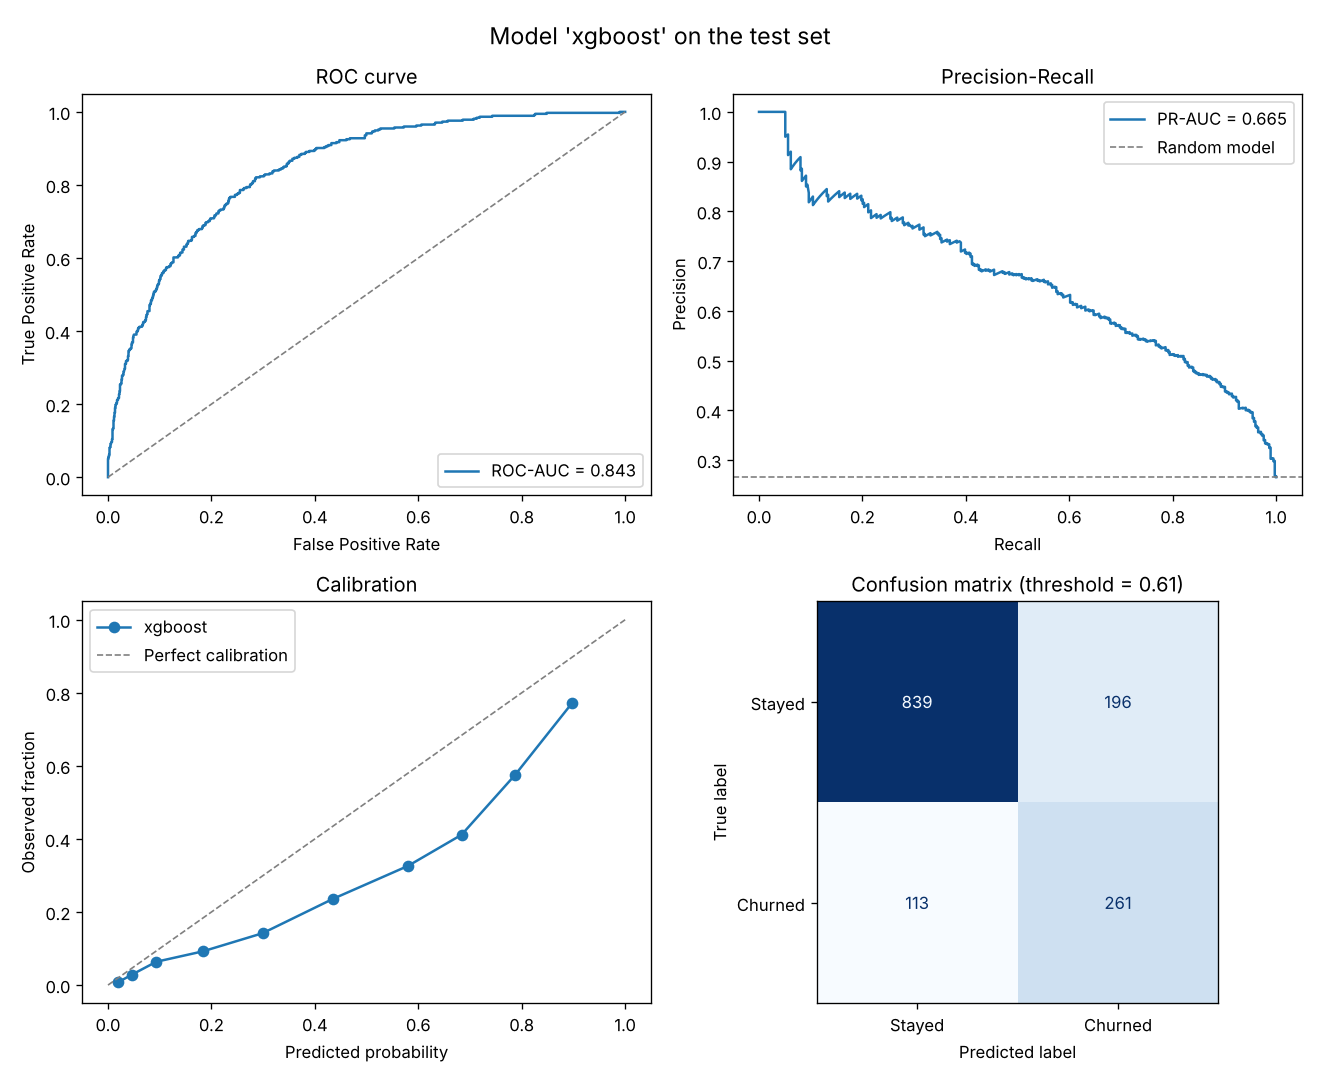

In [5]:
display(Image(config.FIGURES_DIR / "model_report.png"))

**How to read the plots:**
* **Test ROC-AUC ≈ 0.84** matches cross-validation, so the model did not overfit.
* **Confusion matrix.** The model finds ~70% of the customers who actually leave (recall), and ~57% of its
  "alarms" are correct (precision).
* **Calibration.** The curve lies *below* the diagonal, meaning the model overestimates probabilities.
  This is an expected side effect of `scale_pos_weight`: we artificially "boosted" the rare class.
  It does not affect ranking or threshold choice, but if the business needs an honest probability
  ("70% chance this customer leaves"), add `CalibratedClassifierCV` (see "Next steps" in the README).

## 4. Threshold: from probability to decision

0.5 is an arbitrary number. The right threshold depends on the **cost of errors**. Assumptions
(easy to change in `config.py`):

| Parameter | Value | Meaning |
|---|---|---|
| `CUSTOMER_VALUE` | $500 | revenue we keep by retaining a customer |
| `OFFER_COST` | $50 | cost of the offer (discount) |
| `OFFER_SUCCESS_RATE` | 30% | share of customers the offer actually retains |

* **TP** (leaving, we made an offer): `0.3 × 500 − 50 = +$100`
* **FP** (would have stayed, we gave a discount): `−$50`
* **FN, TN:** $0 (we did nothing)

We pick the threshold that maximizes profit **on out-of-fold train predictions**, not on the test set.

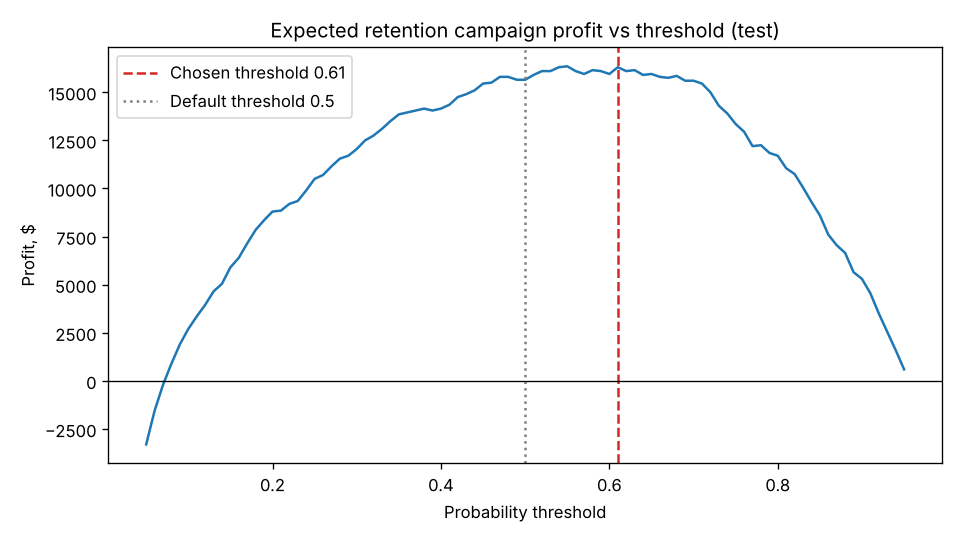

,"Test profit, $"
"Model, chosen threshold",16300.0
"Model, threshold 0.5",15650.0
Offer to everyone,-14350.0
Offer to nobody,0.0


In [6]:
display(Image(config.FIGURES_DIR / "profit_curve.png"))
p = report["profit_test"]
pd.Series({
    "Model, chosen threshold": p["model_at_threshold"],
    "Model, threshold 0.5": p["model_at_0.5"],
    "Offer to everyone": p["contact_everyone"],
    "Offer to nobody": p["contact_nobody"],
}, name="Test profit, $").to_frame()

Sending the discount to everyone *loses* money, because we also pay $50 to customers who would not have left.
The model turns the same campaign into a profitable one. For the business this is the main argument,
far easier to grasp than "AUC 0.84".

## 5. Explaining the model (SHAP)

Metrics tell us *how well* the model works. SHAP tells us *how* it makes decisions.

For every customer SHAP splits the prediction (in logits) into a sum of feature contributions:
`logit(p) = base value + contribution_1 + contribution_2 + …`. A contribution > 0 increases churn risk,
< 0 decreases it.

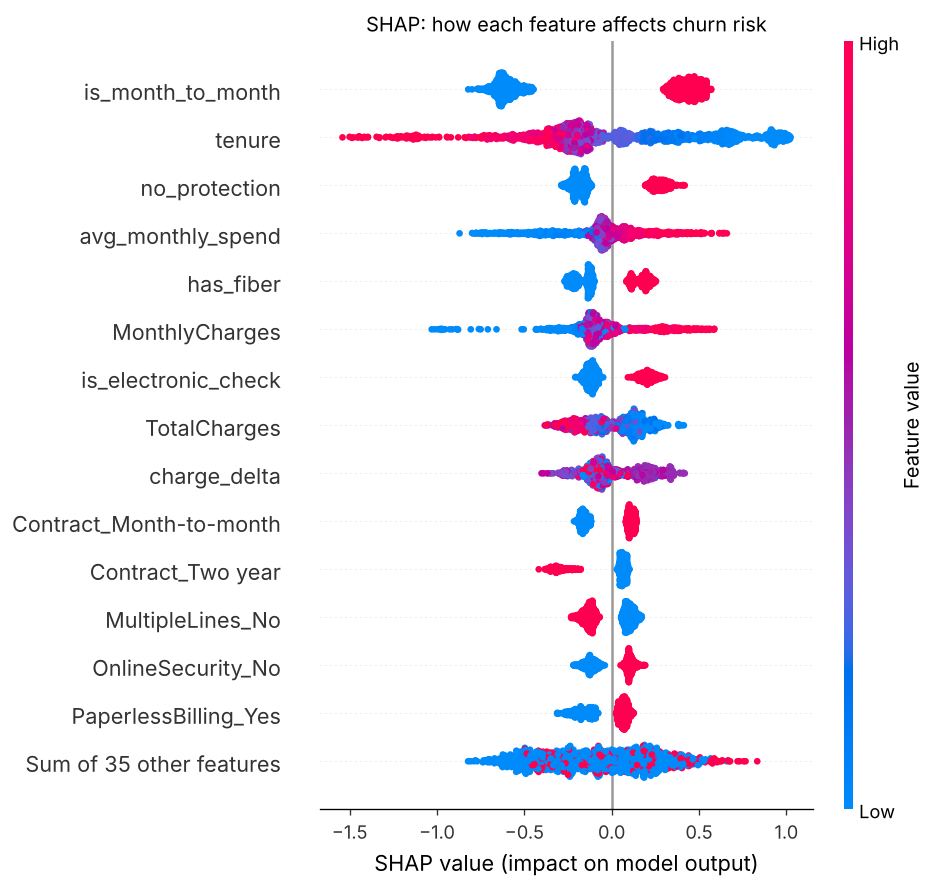

In [7]:
display(Image(config.FIGURES_DIR / "shap_beeswarm.png"))

**How to read the beeswarm:** every dot is a customer; the X position is the feature's contribution; the color is
the feature value (red = high).

* **`is_month_to_month`** is the most important feature. A month-to-month contract (red dots) consistently pushes risk up.
* **`tenure`**: short tenure (blue dots) sharply increases risk, long tenure (red) decreases it.
* **`no_protection`**, **`has_fiber`**, **`is_electronic_check`**: all the features we engineered from the EDA
  made it to the top. This confirms that feature engineering paid off.
* The model "learned" the same things we saw in the EDA plots. That is a good sanity check.

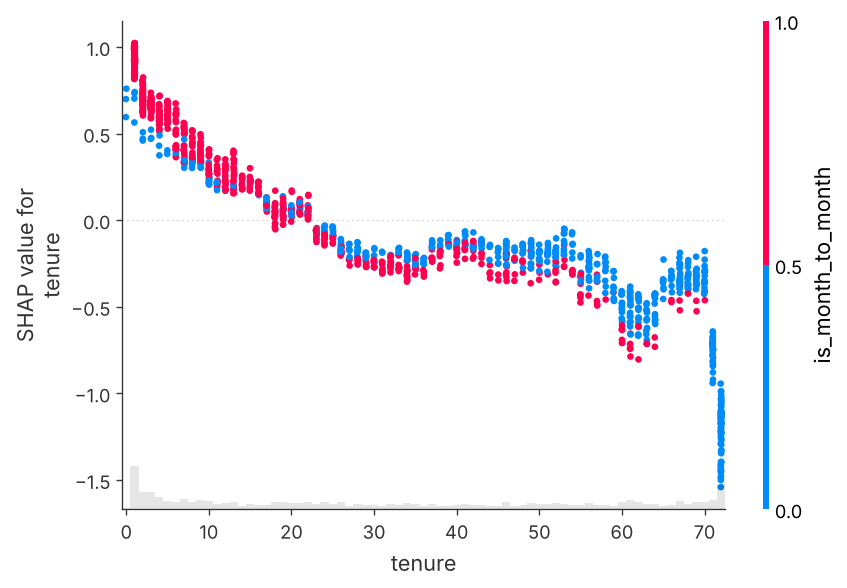

In [8]:
display(Image(config.FIGURES_DIR / "shap_dependence_tenure.png"))

**Dependence plot for `tenure`:** the contribution falls with tenure and turns negative after roughly 1.5–2 years.
The color shows `is_month_to_month`: in the first months a month-to-month contract (red) makes short tenure
even riskier, so the model picked up the interaction we saw on the EDA heatmap.

The sharp drop at `tenure = 72` is a data artifact: tenure in the dataset is capped at 72 months, so all the
most loyal customers (almost all on two-year contracts) pile up there. Such "walls" on plots are worth noticing.

### Explaining a single customer

This is what the API returns in the `top_factors` field: a retention manager sees not just "91% risk"
but also **why**, and can make a relevant offer (for example, a one-year contract or free TechSupport).

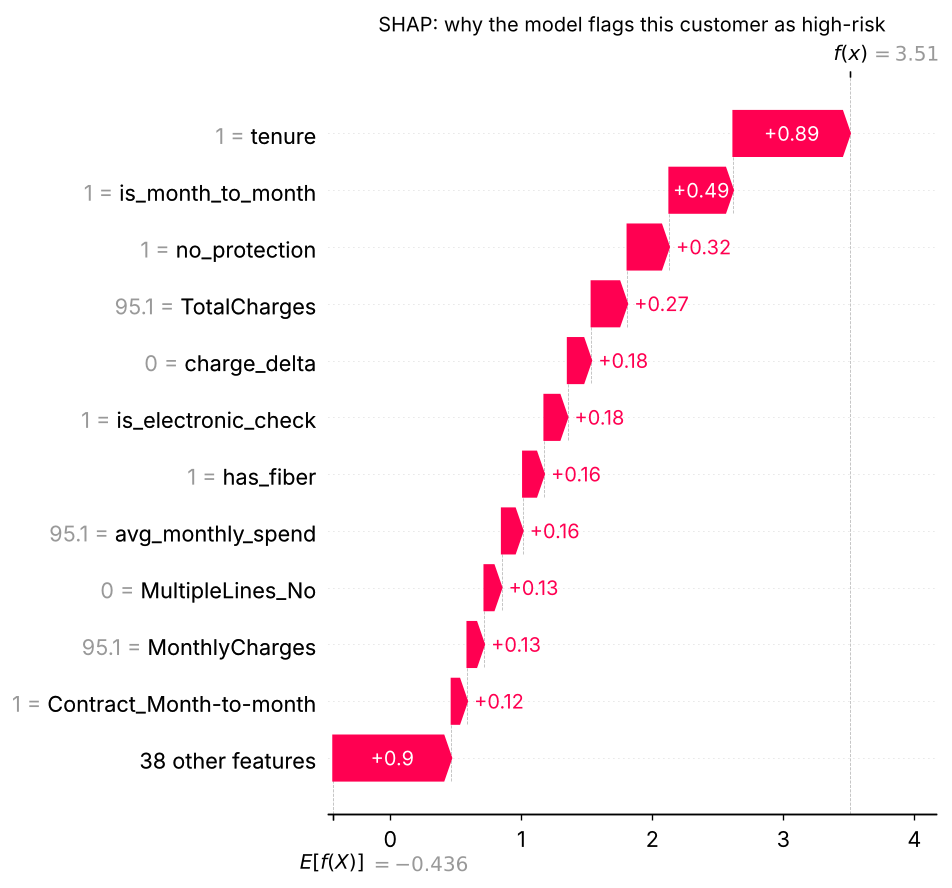

In [9]:
display(Image(config.FIGURES_DIR / "shap_waterfall_example.png"))

In [10]:
sample = X_test.iloc[[0, 1, 2]]
proba = model.predict_proba(sample)
factors = model.explainer.top_factors(sample, k=3)
for (idx, row), p, top in zip(sample.iterrows(), proba, factors, strict=True):
    print(f"Customer {idx}: risk {p:.0%}, tenure={row.tenure}, {row.Contract}, {row.PaymentMethod}")
    for f in top:
        print(f"    {f['feature']:<22} = {f['value']:>7.2f}  {f['impact']:+.2f}  ({f['direction']})")

Customer 437: risk 6%, tenure=72, Two year, Credit card (automatic)
    tenure                 =   72.00  -1.17  (decreases risk)
    is_month_to_month      =    0.00  -0.65  (decreases risk)
    avg_monthly_spend      =  117.61  +0.35  (increases risk)
Customer 2280: risk 89%, tenure=8, Month-to-month, Credit card (automatic)
    tenure                 =    8.00  +0.51  (increases risk)
    is_month_to_month      =    1.00  +0.43  (increases risk)
    MonthlyCharges         =  100.15  +0.33  (increases risk)
Customer 2235: risk 18%, tenure=41, One year, Credit card (automatic)
    is_month_to_month      =    0.00  -0.60  (decreases risk)
    charge_delta           =    0.03  +0.17  (increases risk)
    no_protection          =    0.00  -0.16  (decreases risk)


## Summary

1. Baseline → 4 models → an honest comparison with cross-validation: the models are tied, the data decides.
2. The test set was used once: ROC-AUC 0.84, PR-AUC 0.66.
3. The threshold was chosen by money, not by habit.
4. SHAP shows that the model relies on the same factors as the EDA and explains every prediction.

Next: the model is served via a REST API (`api/main.py`) and Docker. See the README.